In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report

# Set paths to the dataset
base_dir = 'chest_xray'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

In [ ]:
import os

print("Files and folders in your working directory:")
print(os.listdir('.'))

Files and folders in your working directory:
['.config', 'sample_data']


In [ ]:
!pip install kaggle

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

!unzip chest-xray-pneumonia.zip

Streaming output truncated to the last 5000 lines.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating:

In [ ]:
# Data generators
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=20, zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(train_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
val_generator = val_datagen.flow_from_directory(val_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
test_generator = test_datagen.flow_from_directory(test_dir, target_size=(224, 224), batch_size=32, class_mode='binary', shuffle=False)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


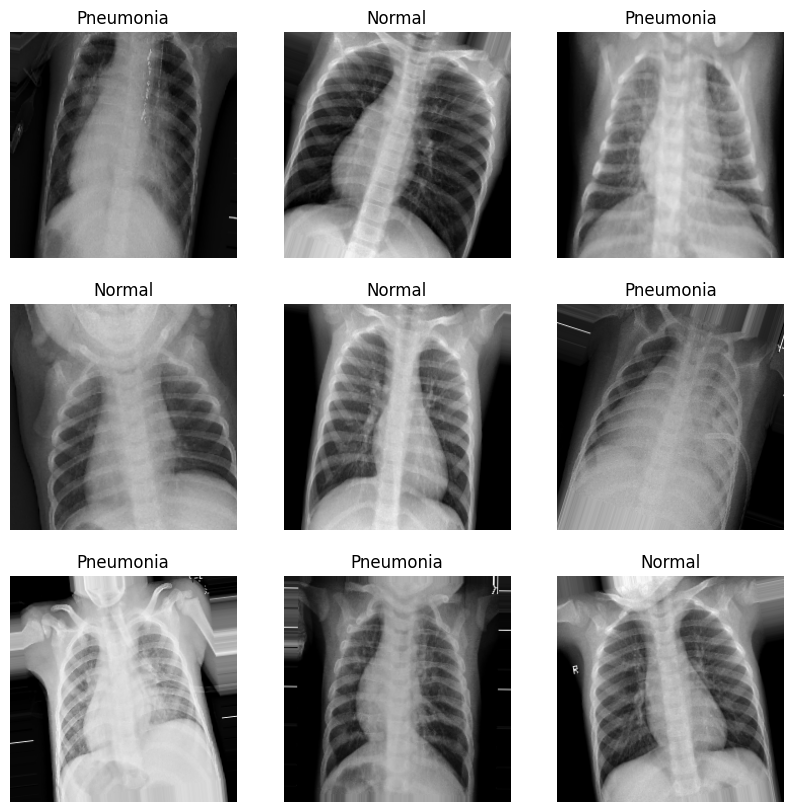

In [ ]:
# Visualize some images from the dataset
def plot_images(generator):
    images, labels = next(generator)
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i])
        plt.title('Pneumonia' if labels[i] else 'Normal')
        plt.axis('off')
    plt.show()

plot_images(train_generator)

In [ ]:
# Choose between VGG16 and ResNet50
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model
base_model.trainable = False

# Add custom layers on top of the base model
x = base_model.output
x = Flatten()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

# Create the model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(train_generator, validation_data=val_generator, epochs=30)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 148s 818ms/step - accuracy: 0.8972 - loss: 0.2476 - val_accuracy: 0.7500 - val_loss: 0.5619
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 125s 763ms/step - accuracy: 0.9425 - loss: 0.1513 - val_accuracy: 0.8125 - val_loss: 0.3358
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 123s 756ms/step - accuracy: 0.9479 - loss: 0.1401 - val_accuracy: 0.7500 - val_loss: 0.4232
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 125s 768ms/step - accuracy: 0.9526 - loss: 0.1224 - val_accuracy: 0.7500 - val_loss: 0.5863
Epoch 5/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 124s 758ms/step - accuracy: 0.9555 - loss: 0.1181 - val_accuracy: 0.7500 - val_loss: 0.5617
Epoch 6/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 123s 756ms/step - accuracy: 0.9611 - loss: 0.1069 - val_accuracy: 0.7500 - val_loss: 0.4789
Epoch 7/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 124s 758ms/step - accuracy: 0.9626 - loss: 0.0999 - val_accuracy: 0.7500 - val_loss: 0.2458
Epoch 8/30
163/163 ━━━━━━

In [ ]:
def plot_learning_curves(history):
    plt.figure(figsize=(12, 4))

    # Plot training & validation loss values
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Plot training & validation accuracy values
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='upper left')

    plt.show()

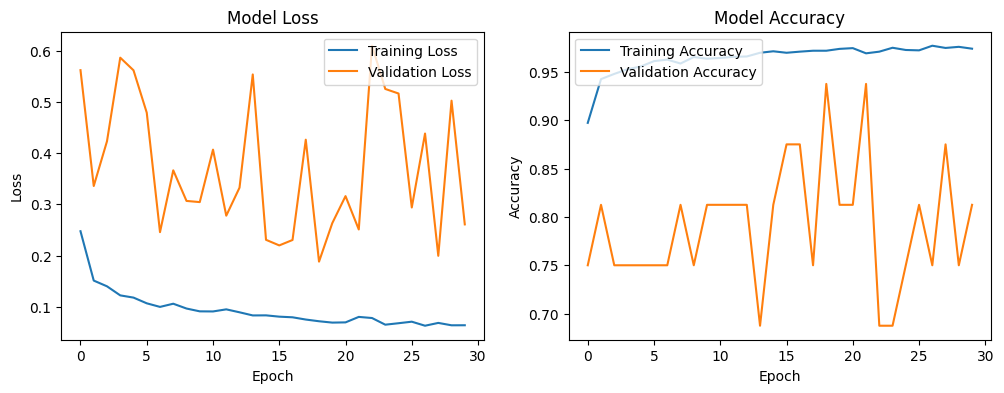

In [ ]:
plot_learning_curves(history)

In [ ]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(test_generator)
print(f'Test Accuracy: {test_acc:.2f}')

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 279ms/step - accuracy: 0.9231 - loss: 0.2509
Test Accuracy: 0.92


In [ ]:
# Predict the labels for the test set
test_generator.reset()
predictions = model.predict(test_generator)
predicted_labels = (predictions > 0.5).astype(int).ravel()


20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 361ms/step


In [ ]:

# Compute the confusion matrix
true_labels = test_generator.classes
cm = confusion_matrix(true_labels, predicted_labels)


In [ ]:
# Plot the confusion matrix
def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

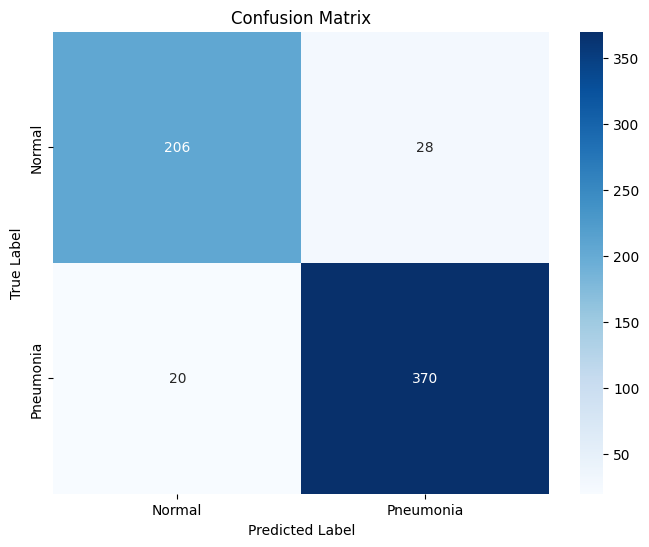

In [ ]:
plot_confusion_matrix(cm, ['Normal', 'Pneumonia'])


In [ ]:
# Print classification report
print(classification_report(true_labels, predicted_labels, target_names=['Normal', 'Pneumonia']))

              precision    recall  f1-score   support

      Normal       0.91      0.88      0.90       234
   Pneumonia       0.93      0.95      0.94       390

    accuracy                           0.92       624
   macro avg       0.92      0.91      0.92       624
weighted avg       0.92      0.92      0.92       624

